# 🤖 Вступ до машинного навчання: лінійна регресія

**Перше заняття з машинного навчання**

Інструменти: `numpy`, `pandas`, `matplotlib`, `scikit-learn`

| # | Тема | Час |
|---|---|---|
| 1 | Що таке машинне навчання (без формул) | 12 хв |
| 2 | Наші дані: ціни квартир | 6 хв |
| 3 | Модель «на око»: пряма лінія і її помилки | 12 хв |
| 4 | Як модель «навчається»: найкраща пряма | 10 хв |
| 5 | Лінійна регресія в scikit-learn | 12 хв |
| 6 | Як оцінити модель: MAE, RMSE, R² | 8 хв |
| 7 | Чому не можна перевіряти модель на тих самих даних | 15 хв |
| 8 | Кілька ознак одразу | 10 хв |
| 9 | Обмеження і підсумок | 5 хв |
| ✍️ | Перевірте себе (домашнє завдання) | — |

> 💡 Ноутбук можна відкрити в **Google Colab**: *File → Upload notebook*. Усі дані генеруються всередині ноутбука. Щоб пройти все з нуля: *Runtime → Run all*.

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
pd.set_option('display.float_format', '{:.2f}'.format)

rng = np.random.default_rng(21)

---
## 1. Що таке машинне навчання (⏱ 12 хв)

### Звичайне програмування

Людина **сама придумує правило** і записує його в код:

```
якщо сума_чеку > 1000:
    дати знижку 5%
```

Це працює, коли правило просте і ми його знаємо.

### А якщо правило складне?

Скільки коштує квартира? Залежить від площі, району, поверху, стану, року будівлі… Ріелтор з досвідом **відчуває** ціну, але записати точне правило не зможе.

Як ріелтор навчився? Він бачив **сотні прикладів** проданих квартир і їхні ціни. З досвідом у нього в голові склалося «правило».

### Машинне навчання — те саме для комп'ютера

> **Машинне навчання (ML)** — це спосіб отримати правило не від людини, а з **прикладів**. Ми даємо комп'ютеру багато прикладів з **правильними відповідями**, а він сам знаходить закономірність.

| | Звичайне програмування | Машинне навчання |
|---|---|---|
| Що даємо | правило + дані | дані + **правильні відповіді** |
| Що отримуємо | відповіді | **правило** (модель) |
| Хто знаходить правило | людина | комп'ютер |

### Головні слова, які будуть потрібні весь курс

| Термін | Що це | Приклад для квартир |
|---|---|---|
| **Об'єкт** | одиниця, про яку робимо прогноз (рядок таблиці) | одна квартира |
| **Ознаки (X)** | те, що ми **знаємо** про об'єкт (стовпці таблиці) | площа, кількість кімнат, відстань до центру |
| **Цільова змінна (y)** | те, що хочемо **передбачити** | ціна |
| **Модель** | знайдене правило: X → y | «ціна ≈ 12 + 1.05 × площа …» |
| **Навчання** (*fit*, *train*) | пошук правила на прикладах з відомими відповідями | |
| **Прогноз** (*predict*) | застосування правила до нових об'єктів | ціна квартири, яку ще не продали |

👀 Пам'ятаєте лекцію про вектори й матриці? **X — це матриця** (рядки — квартири, стовпці — ознаки), а **y — вектор** цін.

### Два основні типи задач «навчання з учителем»

| Тип | Що передбачаємо | Приклади |
|---|---|---|
| **Регресія** | **число** | ціна квартири, виручка завтра, час доставки |
| **Класифікація** | **категорію** | клієнт піде чи залишиться; лист — спам чи ні |

«З учителем» — бо в навчальних даних є правильні відповіді, як у задачника з відповідями в кінці.

**Сьогодні — регресія**, причому найпростіша її версія: **лінійна регресія**.

---
## 2. Наші дані: ціни квартир (⏱ 6 хв)

Згенеруємо 200 проданих квартир. Дані вигадані, але схожі на справжні.

| Колонка | Що означає |
|---|---|
| `area` | площа, м² |
| `rooms` | кількість кімнат |
| `distance` | відстань до центру міста, км |
| `floor` | поверх |
| `price` | ціна продажу, тис. $ — **це наша цільова змінна y** |

In [26]:
n = 200
area = np.round(rng.uniform(30, 120, n))
rooms = np.clip(np.round(area / 28 + rng.normal(0, 0.5, n)), 1, 5).astype(int)
distance = np.round(rng.uniform(1, 15, n), 1)
floor = rng.integers(1, 17, n)
price = np.round(12 + 1.05 * area - 2.2 * distance + 2.0 * rooms + rng.normal(0, 8, n), 1)

flats = pd.DataFrame({'area': area, 'rooms': rooms, 'distance': distance, 'floor': floor, 'price': price})
print('Розмір таблиці:', flats.shape)
flats.head(8)

Розмір таблиці: (200, 5)


,area,rooms,distance,floor,price
0,100.00,3,14.50,11,92.40
1,85.00,2,1.50,16,116.30
2,94.00,3,13.30,9,73.70
3,38.00,1,6.70,10,33.90
4,87.00,4,1.40,8,110.90
5,118.00,5,6.60,14,144.70
6,68.00,2,9.40,4,58.40
7,40.00,2,6.20,4,41.20


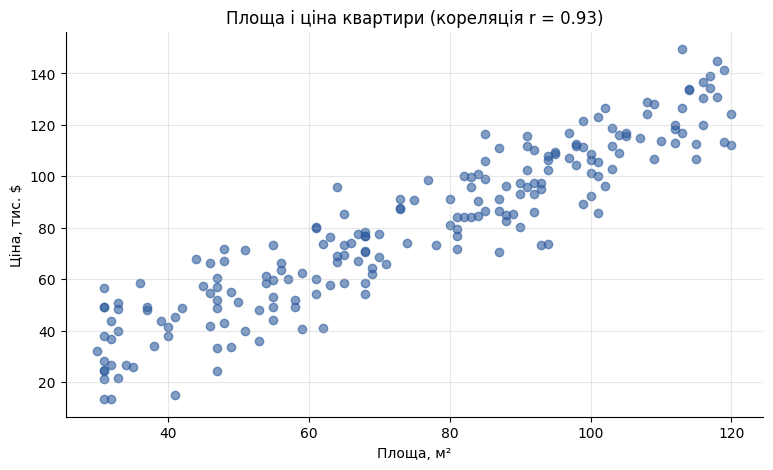

In [27]:
plt.scatter(flats['area'], flats['price'], alpha=0.6, color='#2E5C9E')
plt.title(f"Площа і ціна квартири (кореляція r = {flats['area'].corr(flats['price']):.2f})")
plt.xlabel('Площа, м²')
plt.ylabel('Ціна, тис. $')
plt.show()

Чітко видно **позитивний лінійний зв'язок**: що більша квартира, то вона дорожча. Але точки не лежать рівно на лінії — на ціну впливає ще й район, кількість кімнат і просто випадковість.

**Задача:** знайти правило, за яким можна оцінити ціну **будь-якої** квартири за її площею.

---
## 3. Модель «на око»: пряма лінія і її помилки (⏱ 12 хв)

### Рівняння прямої

Найпростіше правило — **пряма лінія**:

$$\text{ціна} = a + b \cdot \text{площа}$$

| Параметр | Назва | Що означає |
|---|---|---|
| **b** | нахил (*slope*), коефіцієнт | на скільки зростає ціна, коли площа зростає на **1 м²** |
| **a** | вільний член (*intercept*) | «ціна» при площі 0 м² — точка, де пряма перетинає вісь Y |

Наприклад, правило «ціна = 10 + 0.9 × площа» означає: кожен квадратний метр додає 900 $, плюс «базові» 10 тис. $.

### Спробуємо підібрати пряму на око

Уявімо, що двоє студентів запропонували свої прямі. Яка краща?

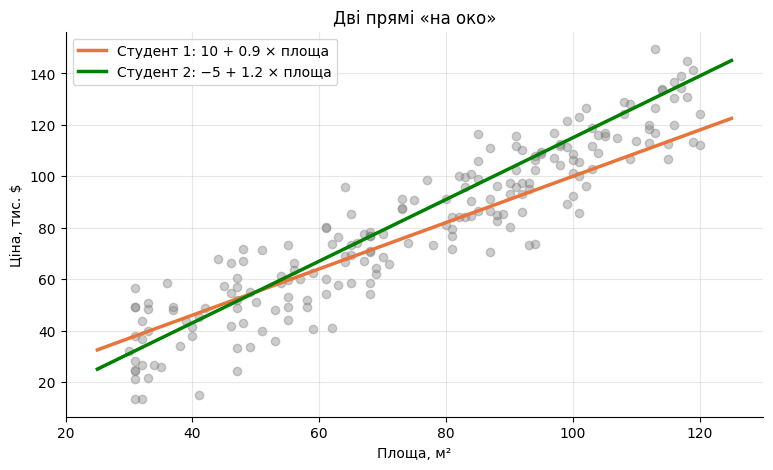

In [28]:
def line_1(x): return 10 + 0.9 * x       # пропозиція студента 1
def line_2(x): return -5 + 1.2 * x       # пропозиція студента 2

xs = np.array([25, 125])
plt.scatter(flats['area'], flats['price'], alpha=0.4, color='gray')
plt.plot(xs, line_1(xs), color='#E8743B', linewidth=2.5, label='Студент 1: 10 + 0.9 × площа')
plt.plot(xs, line_2(xs), color='green', linewidth=2.5, label='Студент 2: −5 + 1.2 × площа')
plt.title('Дві прямі «на око»')
plt.xlabel('Площа, м²')
plt.ylabel('Ціна, тис. $')
plt.legend()
plt.show()

Обидві виглядають «приблизно правильно». Щоб порівняти чесно, потрібна **міра помилки**.

### Помилка прогнозу

Для кожної квартири порівнюємо **справжню** ціну y з **прогнозом** ŷ («ігрек з шапкою»):

$$\text{помилка} = y - \hat{y}$$

На графіку помилка — це **вертикальна відстань** від точки до прямої. Подивимось на 15 квартир:

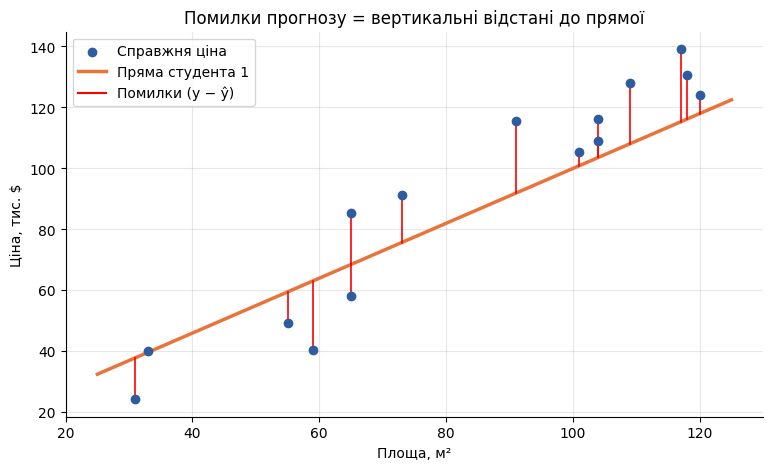

In [29]:
sample = flats.sample(15, random_state=3)
pred = line_1(sample['area'])

plt.scatter(sample['area'], sample['price'], color='#2E5C9E', zorder=3, label='Справжня ціна')
plt.plot(xs, line_1(xs), color='#E8743B', linewidth=2.5, label='Пряма студента 1')
for x, y, p in zip(sample['area'], sample['price'], pred):
    plt.plot([x, x], [y, p], color='red', linewidth=1.2)
plt.plot([], [], color='red', label='Помилки (y − ŷ)')
plt.title('Помилки прогнозу = вертикальні відстані до прямої')
plt.xlabel('Площа, м²')
plt.ylabel('Ціна, тис. $')
plt.legend()
plt.show()

### Як звести всі помилки в одне число

Помилки бувають додатні (точка вище прямої) і від'ємні (нижче). Якщо їх просто скласти, вони взаємно знищаться. Тому:

| Метрика | Формула | Що означає |
|---|---|---|
| **MAE** — середня абсолютна помилка | середнє від \|y − ŷ\| | «у середньому модель помиляється на … тис. $» — найзрозуміліша |
| **MSE** — середня квадратична помилка | середнє від (y − ŷ)² | великі помилки «штрафуються» сильніше (бо в квадраті) |

Це та сама ідея, що й з дисперсією: щоб плюси й мінуси не знищили один одного, беремо модуль або квадрат.

In [30]:
y = flats['price']
for name, f in [('Студент 1', line_1), ('Студент 2', line_2)]:
    y_hat = f(flats['area'])
    errors = y - y_hat
    mae = errors.abs().mean()
    mse = (errors ** 2).mean()
    print(f'{name}: MAE = {mae:5.2f} тис. $ | MSE = {mse:7.1f}')

Студент 1: MAE = 10.47 тис. $ | MSE =   168.3
Студент 2: MAE = 10.18 тис. $ | MSE =   161.7


Пряма студента 2 помиляється в середньому трохи менше — за цією мірою вона краща, хоча на графіку різницю важко помітити на око.

Але чи це **найкраща можлива** пряма? Перебирати прямі вручну можна вічно. Нехай це зробить комп'ютер.

---
## 4. Як модель «навчається»: найкраща пряма (⏱ 10 хв)

> **«Навчити модель»** = знайти такі параметри a і b, за яких **помилка на навчальних даних найменша**.

Лінійна регресія шукає пряму з найменшою **сумою квадратів помилок**. Тому метод називають **методом найменших квадратів** (*Ordinary Least Squares*, OLS).

### Подивімося, як це виглядає

Переберемо багато значень нахилу b (для кожного підберемо найкраще a) і порахуємо помилку. Отримаємо криву — і шукаємо її **найнижчу точку**.

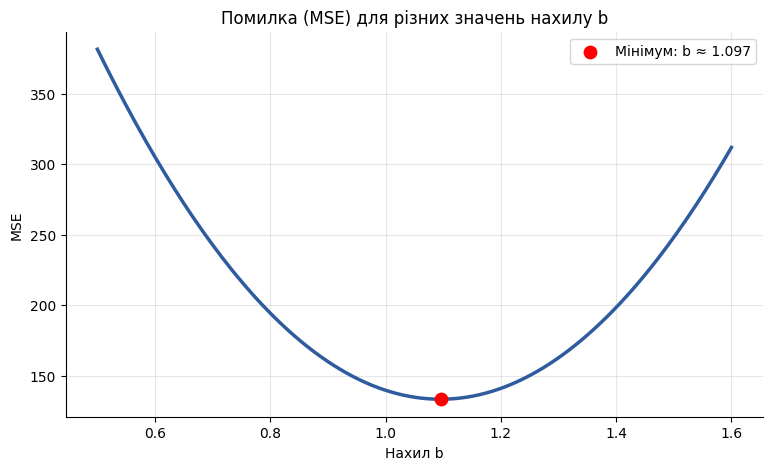

In [31]:
x, y = flats['area'], flats['price']
slopes = np.linspace(0.5, 1.6, 200)
mse_list = []
for b in slopes:
    a = y.mean() - b * x.mean()            # найкраще a для цього b
    mse_list.append(((y - (a + b * x)) ** 2).mean())

best_b = slopes[np.argmin(mse_list)]
plt.plot(slopes, mse_list, color='#2E5C9E', linewidth=2.5)
plt.scatter([best_b], [min(mse_list)], color='red', s=80, zorder=3, label=f'Мінімум: b ≈ {best_b:.3f}')
plt.title('Помилка (MSE) для різних значень нахилу b')
plt.xlabel('Нахил b')
plt.ylabel('MSE')
plt.legend()
plt.show()

Крива має форму «чаші», і в неї **одна найнижча точка**. Саме це значення b дає найкращу пряму.

### Для однієї ознаки є точна формула

Перебирати навіть не потрібно — є формула, і в ній знайомі нам поняття з лекції про кореляцію:

$$b = \frac{\text{cov}(x, y)}{\text{var}(x)}, \qquad a = \bar{y} - b \cdot \bar{x}$$

- **Нахил** — коваріація площі й ціни, поділена на дисперсію площі.
- **Вільний член** підбирається так, щоб пряма проходила через точку (середня площа, середня ціна).

In [32]:
b_formula = x.cov(y) / x.var()
a_formula = y.mean() - b_formula * x.mean()
print(f'Найкраща пряма за формулою: ціна = {a_formula:.2f} + {b_formula:.3f} × площа')

Найкраща пряма за формулою: ціна = -1.71 + 1.095 × площа


> 💡 **Головна думка розділу:** в ML немає магії. «Навчання» — це **пошук параметрів моделі, за яких помилка на прикладах найменша**. Для лінійної регресії ця задача розв'язується точно; для складніших моделей комп'ютер шукає мінімум крок за кроком, але ідея та сама.

---
## 5. Лінійна регресія в scikit-learn (⏱ 12 хв)

**scikit-learn** (`sklearn`) — найпопулярніша бібліотека класичного машинного навчання в Python. Усі моделі в ній працюють **за однією схемою з трьох кроків**:

```python
model = LinearRegression()   # 1. створити модель («пустий учень»)
model.fit(X, y)              # 2. навчити на прикладах (X — ознаки, y — правильні відповіді)
model.predict(X_new)         # 3. зробити прогноз для нових об'єктів
```

Вивчите цю схему один раз — і зможете використовувати десятки інших моделей.

### ⚠️ X має бути таблицею (матрицею), а не одним стовпцем

`sklearn` очікує, що X — це **2D**: рядки — об'єкти, стовпці — ознаки. Навіть якщо ознака одна.
- `flats[['area']]` — **подвійні** дужки → таблиця з одним стовпцем, форма (200, 1) ✅
- `flats['area']` — одинарні дужки → просто вектор, форма (200,) ❌

In [33]:
X = flats[['area']]      # ознаки — ПОДВІЙНІ дужки
y = flats['price']       # ціль — одинарні
print('X:', X.shape, '| y:', y.shape)

X: (200, 1) | y: (200,)


In [34]:
# Що буде з одинарними дужками
try:
    LinearRegression().fit(flats['area'], y)
except ValueError as e:
    print('Помилка:', str(e)[:120], '...')

Помилка: Expected a 2-dimensional container but got <class 'pandas.core.series.Series'> instead. Pass a DataFrame containing a si ...


In [35]:
model = LinearRegression()
model.fit(X, y)

print(f'Нахил b (coef_):            {model.coef_[0]:.3f}')
print(f'Вільний член a (intercept_): {model.intercept_:.2f}')
print(f'\nМодель: ціна = {model.intercept_:.2f} + {model.coef_[0]:.3f} × площа')

Нахил b (coef_):            1.095
Вільний член a (intercept_): -1.71

Модель: ціна = -1.71 + 1.095 × площа


Числа збіглися з формулою з розділу 4 — sklearn зробив те саме, що ми, тільки одним рядком.

### Як читати коефіцієнт

**b ≈ 1.1**: кожен додатковий квадратний метр у середньому додає до ціни приблизно **1.1 тис. $** (≈ 1100 $ за м²).

### Прогноз для нових квартир

Ось момент, заради якого все робиться: оцінимо квартири, **яких не було в наших даних**.

In [36]:
new_flats = pd.DataFrame({'area': [40, 65, 100]})
new_flats['predicted_price'] = model.predict(new_flats[['area']])
new_flats

,area,predicted_price
0,40,42.09
1,65,69.47
2,100,107.80


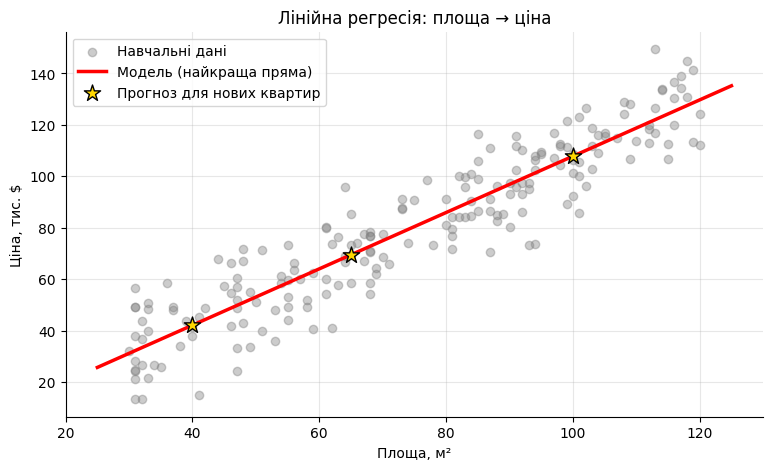

In [37]:
xs = pd.DataFrame({'area': [25, 125]})
plt.scatter(flats['area'], flats['price'], alpha=0.4, color='gray', label='Навчальні дані')
plt.plot(xs['area'], model.predict(xs), color='red', linewidth=2.5, label='Модель (найкраща пряма)')
plt.scatter(new_flats['area'], new_flats['predicted_price'], color='gold', edgecolor='black', s=150,
            zorder=3, marker='*', label='Прогноз для нових квартир')
plt.title('Лінійна регресія: площа → ціна')
plt.xlabel('Площа, м²')
plt.ylabel('Ціна, тис. $')
plt.legend()
plt.show()

---
## 6. Як оцінити модель: MAE, RMSE, R² (⏱ 8 хв)

| Метрика | Що показує | Як читати | Функція |
|---|---|---|---|
| **MAE** | середня абсолютна помилка | «помиляємось у середньому на … тис. $». Чим менше, тим краще | `mean_absolute_error(y, y_pred)` |
| **RMSE** | корінь з MSE | теж у тис. $, але сильніше «карає» великі помилки | `np.sqrt(mean_squared_error(y, y_pred))` |
| **R²** | частка розкиду y, яку пояснює модель | від 0 до 1 (чим ближче до 1, тим краще). R² = 0 — модель не краща за «завжди прогнозувати середнє» | `r2_score(y, y_pred)` |

👀 Для однієї ознаки **R² = r²** — квадрат кореляції з минулого заняття!

In [38]:
y_pred = model.predict(X)

mae = mean_absolute_error(y, y_pred)
rmse = np.sqrt(mean_squared_error(y, y_pred))
r2 = r2_score(y, y_pred)

print(f'MAE  = {mae:.2f} тис. $')
print(f'RMSE = {rmse:.2f} тис. $')
print(f'R²   = {r2:.3f}   (а квадрат кореляції r² = {flats["area"].corr(flats["price"]) ** 2:.3f})')

MAE  = 9.42 тис. $
RMSE = 11.54 тис. $
R²   = 0.863   (а квадрат кореляції r² = 0.863)


**Як це пояснити замовнику:** «Модель за площею вгадує ціну квартири в середньому з точністю ±{MAE} тис. $ і пояснює близько {R²×100}% різниці в цінах. Решта залежить від інших чинників — району, кімнат тощо».

Чи хороший це результат? **Залежить від задачі.** Для оцінки ринку — можливо, так. Для ріелтора, якому помилка в 10 тис. $ коштує угоди, — ні.

### ⚠️ Але є проблема

Ми навчили модель на 200 квартирах і **перевірили на тих самих 200 квартирах**. Чи можна довіряти таким цифрам? Про це — наступний, найважливіший розділ.

---
## 7. Чому не можна перевіряти модель на тих самих даних (⏱ 15 хв)

### Аналогія: іспит

Викладач дав студентам 30 білетів з відповідями для підготовки. На іспиті — **ті самі 30 білетів**.

- Студент А **розібрався** в предметі → відповів добре.
- Студент Б **завчив відповіді напам'ять**, нічого не розуміючи → теж відповів добре!

Іспит їх не розрізнив. Щоб перевірити справжнє розуміння, треба дати **нові білети**, яких студенти не бачили.

### З моделями так само

Модель може **«завчити» навчальні дані** разом з усім випадковим шумом, замість того щоб знайти загальну закономірність. Це називається **перенавчання** (*overfitting*). На знайомих даних така модель виглядає чудово, а на нових — працює погано.

А нам потрібна модель саме для **нових** даних (квартир, які ще не продали).

### Демонстрація перенавчання

Візьмемо лише 10 квартир для навчання і порівняємо дві моделі:
- **проста:** пряма лінія;
- **складна:** крива 9-го степеня, яка може «вигнутися» як завгодно.

In [39]:
small = flats.sample(10, random_state=3)            # 10 квартир для навчання
rest = flats.drop(small.index)                       # решта — «нові» квартири
# Для чесного порівняння беремо нові квартири з того самого діапазону площ, що й навчальні
rest = rest[(rest['area'] >= small['area'].min()) & (rest['area'] <= small['area'].max())]

# Масштабуємо площу (ділимо на 100), щоб крива 9-го степеня рахувалася стабільно
xs_small, ys_small = small['area'] / 100, small['price']
simple = np.polyfit(xs_small, ys_small, deg=1)       # пряма
complex_ = np.polyfit(xs_small, ys_small, deg=9)     # «вигнута» крива через усі точки

def mae_of(coefs, data):
    return np.mean(np.abs(data['price'] - np.polyval(coefs, data['area'] / 100)))

print(f'                     На навчальних (10 шт.)   На нових ({len(rest)} шт.)')
print(f'Проста (пряма):       MAE = {mae_of(simple, small):6.2f}           MAE = {mae_of(simple, rest):8.2f}')
print(f'Складна (9-й степ.):  MAE = {mae_of(complex_, small):6.2f}           MAE = {mae_of(complex_, rest):8.2f}')

                     На навчальних (10 шт.)   На нових (189 шт.)
Проста (пряма):       MAE =   6.28           MAE =    10.45
Складна (9-й степ.):  MAE =   0.00           MAE =    30.48


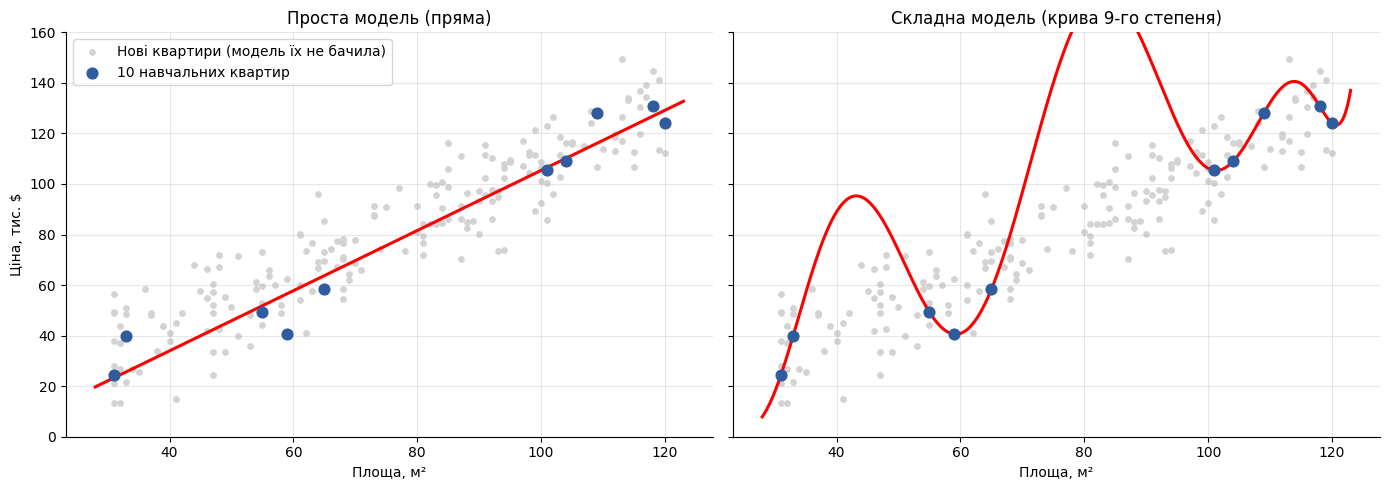

In [40]:
grid = np.linspace(small['area'].min() - 3, small['area'].max() + 3, 400)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, coefs, title in [(axes[0], simple, 'Проста модель (пряма)'),
                         (axes[1], complex_, 'Складна модель (крива 9-го степеня)')]:
    ax.scatter(rest['area'], rest['price'], color='lightgray', s=15, label='Нові квартири (модель їх не бачила)')
    ax.scatter(small['area'], small['price'], color='#2E5C9E', s=60, zorder=3, label='10 навчальних квартир')
    ax.plot(grid, np.polyval(coefs, grid / 100), color='red', linewidth=2.2)
    ax.set_ylim(0, 160)
    ax.set_title(title)
    ax.set_xlabel('Площа, м²')
axes[0].set_ylabel('Ціна, тис. $')
axes[0].legend(loc='upper left')
plt.tight_layout()
plt.show()

**Що сталося:**
- Складна крива проходить **точно через кожну** з 10 навчальних точок: помилка на них ≈ 0. Виглядає як «ідеальна модель»!
- Але між точками вона робить дикі вигини, і на нових квартирах помиляється **приблизно втричі гірше** за просту пряму.

Складна модель **завчила** 10 прикладів разом із шумом. Проста — вловила **загальну тенденцію**.

> 💡 **Якби ми перевіряли лише на навчальних даних, ми б обрали гіршу модель.** Тому оцінка на тих самих даних, на яких модель навчалась, — **обман себе**.

### Рішення: розділити дані на навчальні й тестові

| Частина | Розмір (зазвичай) | Для чого |
|---|---|---|
| **Навчальна** (*train*) | 70–80% | модель навчається тільки на ній |
| **Тестова** (*test*) | 20–30% | «нові білети»: модель їх **не бачить** під час навчання; тут чесно оцінюємо якість |

**Правило:** тестові дані — як запечатаний конверт з білетами. Його відкривають **один раз, у самому кінці**, щоб оцінити готову модель.

У sklearn це робить `train_test_split`. Параметр `random_state` фіксує випадкове розбиття, щоб у всіх вийшов однаковий результат.

In [41]:
X = flats[['area']]
y = flats['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print('Навчальна вибірка:', X_train.shape, '| Тестова:', X_test.shape)

Навчальна вибірка: (150, 1) | Тестова: (50, 1)


In [42]:
model_1 = LinearRegression()
model_1.fit(X_train, y_train)                 # навчаємо ТІЛЬКИ на train

mae_train = mean_absolute_error(y_train, model_1.predict(X_train))
mae_test = mean_absolute_error(y_test, model_1.predict(X_test))
r2_test = r2_score(y_test, model_1.predict(X_test))

print(f'MAE на навчальних даних: {mae_train:.2f} тис. $')
print(f'MAE на тестових даних:   {mae_test:.2f} тис. $   ← це чесна оцінка')
print(f'R² на тестових даних:    {r2_test:.3f}')

MAE на навчальних даних: 9.34 тис. $
MAE на тестових даних:   9.66 тис. $   ← це чесна оцінка
R² на тестових даних:    0.870


Для простої прямої помилки на навчальних і тестових даних **близькі** — ознака того, що модель не перенавчилась. Якщо ж помилка на тесті **набагато більша**, ніж на навчальних даних, — це сигнал перенавчання.

| Що бачимо | Діагноз |
|---|---|
| train ≈ test, обидві прийнятні | ✅ модель узагальнює |
| train маленька, test велика | ⚠️ **перенавчання**: модель завчила дані |
| обидві великі | ⚠️ **недонавчання**: модель занадто проста або бракує ознак |

---
## 8. Кілька ознак одразу (⏱ 10 хв)

Ціна залежить не лише від площі. Додамо **кількість кімнат** і **відстань до центру**. Рівняння стає:

$$\text{ціна} = a + b_1 \cdot \text{площа} + b_2 \cdot \text{кімнати} + b_3 \cdot \text{відстань}$$

Це вже не пряма на площині (її не намалюєш), але ідея та сама: шукаємо коефіцієнти з найменшою помилкою. **У коді змінюється лише список стовпців у X.**

👀 Прогноз для однієї квартири — це **скалярний добуток** вектора ознак на вектор коефіцієнтів плюс a. Знову лінійна алгебра!

In [43]:
features = ['area', 'rooms', 'distance']
X3 = flats[features]
X3_train, X3_test, y_train, y_test = train_test_split(X3, y, test_size=0.25, random_state=42)

model_3 = LinearRegression()
model_3.fit(X3_train, y_train)

print('Коефіцієнти:')
for name, coef in zip(features, model_3.coef_):
    print(f'  {name:9}: {coef:+.3f}')
print(f'  intercept: {model_3.intercept_:+.3f}')

Коефіцієнти:
  area     : +1.013
  rooms    : +3.754
  distance : -2.272
  intercept: +11.623


### Як читати коефіцієнти: «за інших рівних»

Кожен коефіцієнт показує, як зміниться прогноз, якщо змінити **лише цю** ознаку, а решту залишити **такими самими**:

- **area ≈ +1.0:** +1 м² → ціна вища приблизно на 1 тис. $ (при тих самих кімнатах і відстані).
- **rooms ≈ +3.7:** ще одна кімната **при тій самій площі** → дорожче приблизно на 3.7 тис. $.
- **distance ≈ −2.2:** кожен кілометр від центру **здешевлює** квартиру приблизно на 2.2 тис. $.

Знак «−» означає, що зі зростанням ознаки ціна падає.

In [44]:
mae_1 = mean_absolute_error(y_test, model_1.predict(X_test))
mae_3 = mean_absolute_error(y_test, model_3.predict(X3_test))
r2_1 = r2_score(y_test, model_1.predict(X_test))
r2_3 = r2_score(y_test, model_3.predict(X3_test))

pd.DataFrame({'MAE на тесті, тис. $': [mae_1, mae_3], 'R² на тесті': [r2_1, r2_3]},
             index=['1 ознака (площа)', '3 ознаки'])

,"MAE на тесті, тис. $",R² на тесті
1 ознака (площа),9.66,0.87
3 ознаки,6.67,0.93


З трьома ознаками помилка помітно менша, а R² вищий: модель отримала більше корисної інформації.

### А якщо додати непотрібну ознаку?

Поверх ніяк не впливав на ціну в наших даних (ми так їх згенерували). Що зробить модель?

In [45]:
features_4 = ['area', 'rooms', 'distance', 'floor']
X4_train, X4_test, _, _ = train_test_split(flats[features_4], y, test_size=0.25, random_state=42)
model_4 = LinearRegression().fit(X4_train, y_train)

for name, coef in zip(features_4, model_4.coef_):
    print(f'  {name:9}: {coef:+.3f}')
print(f'\nMAE на тесті: {mean_absolute_error(y_test, model_4.predict(X4_test)):.2f} (з 3 ознаками було {mae_3:.2f})')

  area     : +1.013
  rooms    : +3.731
  distance : -2.262
  floor    : +0.081

MAE на тесті: 6.70 (з 3 ознаками було 6.67)


Коефіцієнт поверху близький до нуля: модель «зрозуміла», що ця ознака майже не допомагає. Якість майже не змінилась.

Але на малих даних і з **багатьма** непотрібними ознаками модель може почати підлаштовуватися під шум, тобто перенавчатися. Тому ознаки варто додавати **з розумом**, а не всі підряд.

In [46]:
# Прогноз для нової квартири з усіма трьома ознаками
new_flat = pd.DataFrame({'area': [70], 'rooms': [3], 'distance': [4.0]})
print(f'Прогноз ціни: {model_3.predict(new_flat)[0]:.1f} тис. $')

# Те саме вручну: a + b1·x1 + b2·x2 + b3·x3 — скалярний добуток!
manual = model_3.intercept_ + new_flat.iloc[0].to_numpy() @ model_3.coef_
print(f'Вручну:       {manual:.1f} тис. $')

Прогноз ціни: 84.7 тис. $
Вручну:       84.7 тис. $


---
## 9. Обмеження і підсумок (⏱ 5 хв)

### ⚠️ Про що пам'ятати

1. **Лінійна модель бачить лише лінійні зв'язки.** Якщо зв'язок криволінійний, пряма його погано опише (згадайте «перевернуту U» з лекції про кореляцію).
2. **Не екстраполюйте далеко.** Модель навчалась на квартирах 30–120 м². Прогноз для 500 м² чи 5 м² може бути безглуздим. Вільний член a — «ціна квартири 0 м²» — часто не має реального змісту.
3. **Коефіцієнт ≠ причина.** Модель знаходить зв'язки в даних, але не доводить причинність (кореляція ≠ причинність!).
4. **Якість даних = якість моделі.** Помилки й викиди в даних псують модель (згадайте, як викид змінював кореляцію).

### Типовий процес ML-проєкту

| Крок | Що робимо | Код |
|---|---|---|
| 1 | Сформулювати задачу: що передбачаємо (y) і за чим (X) | |
| 2 | Подивитися на дані: графіки, кореляції, викиди | `scatter`, `corr()` |
| 3 | Розділити на train і test | `train_test_split` |
| 4 | Навчити модель на train | `model.fit(X_train, y_train)` |
| 5 | Оцінити на test | `mean_absolute_error`, `r2_score` |
| 6 | Інтерпретувати і використовувати для прогнозів | `model.coef_`, `model.predict` |

### 5 речей, які варто запам'ятати

1. **ML — це пошук правила з прикладів**, а не ручне написання правила.
2. **Лінійна регресія** шукає пряму (або площину) з найменшою сумою квадратів помилок.
3. **scikit-learn:** `fit` → `predict`. X — таблиця з подвійними дужками.
4. **MAE** — середня помилка в зрозумілих одиницях; **R²** — яку частку розкиду пояснює модель.
5. **Ніколи не оцінюйте модель на тих самих даних, на яких вона навчалась.** Відкладіть тестову вибірку.

---
## ✍️ Перевірте себе (домашнє завдання)

Під кожним завданням — порожня клітинка для коду.

**Завдання 1.** Для кожної задачі визначте, це регресія чи класифікація, і що в ній ознаки X, а що ціль y:

   а) передбачити, скільки кави продасть кав'ярня завтра;
   б) визначити, чи відкриє клієнт email-розсилку;
   в) оцінити вартість ремонту за площею і типом квартири.

**а) Скільки кави продасть кав'ярня завтра?**

- Тип задачі: регресія.
- X: день тижня, погода, свята, попередні продажі.
- y: кількість проданих чашок кави.

**б) Чи відкриє клієнт email-розсилку?**

- Тип задачі: класифікація.
- X: історія відкриттів листів, тема листа, час відправлення.
- y: відкрив лист чи ні (так/ні).

**в) Яка вартість ремонту квартири?**

- Тип задачі: регресія.
- X: площа та тип квартири.
- y: вартість ремонту.

**Завдання 2.** Навчіть лінійну регресію ціни квартири лише на ознаці `distance` (train/test як у лекції: `test_size=0.25, random_state=42`). Який коефіцієнт і як його пояснити? Порівняйте MAE на тесті з моделлю за площею.

In [47]:
# Вибираємо ознаку X — відстань квартири до центру
Xd = flats[['distance']]

# Розділяємо дані: 75% для навчання, 25% для тестування
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    Xd, y, test_size=0.25, random_state=42
)

# Створюємо та навчаємо модель лінійної регресії
m_d = LinearRegression()
m_d.fit(Xd_train, yd_train)

# Отримуємо коефіцієнт відстані
coef_distance = m_d.coef_[0]

# Прогнозуємо ціни квартир на тестових даних
yd_pred = m_d.predict(Xd_test)

# Розраховуємо середню абсолютну помилку
mae_distance = mean_absolute_error(yd_test, yd_pred)

# Виводимо результати
print(f'Коефіцієнт distance: {coef_distance:.2f} тис. $ за км')
print(f'MAE за відстанню: {mae_distance:.2f} тис. $')
print(f'MAE за площею: {mae_1:.2f} тис. $')

Коефіцієнт distance: -1.29 тис. $ за км
MAE за відстанню: 28.54 тис. $
MAE за площею: 9.66 тис. $


Коефіцієнт відстані становить −1.29, тобто зі збільшенням відстані від центру на 1 км прогнозована ціна квартири зменшується приблизно на 1.29 тис. $.

Модель за відстанню має MAE = 28.54 тис. $, тоді як модель за площею — 9.66 тис. $.

Отже, модель за площею значно точніша. На цих даних площа квартири є кращою ознакою для прогнозування ціни, ніж відстань до центру.

**Завдання 3.** За моделлю `model_3` оцініть ціну двох квартир: 45 м², 1 кімната, 12 км від центру; 95 м², 4 кімнати, 2 км від центру. Яка різниця в ціні?

In [48]:
# Створюємо таблицю з характеристиками двох квартир
two = pd.DataFrame({
    'area': [45, 95],       # Площа квартир у м²
    'rooms': [1, 4],        # Кількість кімнат
    'distance': [12, 2]     # Відстань до центру в км
})

# Прогнозуємо ціни за допомогою вже навченої моделі
p = model_3.predict(two)

# Обчислюємо різницю між прогнозованими цінами
difference = p[1] - p[0]

# Виводимо результати
print(f'Квартира 1: {p[0]:.1f} тис. $')
print(f'Квартира 2: {p[1]:.1f} тис. $')
print(f'Різниця в ціні: {difference:.1f} тис. $')

Квартира 1: 33.7 тис. $
Квартира 2: 118.4 тис. $
Різниця в ціні: 84.6 тис. $


За прогнозом моделі лінійної регресії, перша квартира (45 м², 1 кімната, 12 км від центру) коштує приблизно 33.7 тис. $, а друга (95 м², 4 кімнати, 2 км від центру) — 118.4 тис. $.

Різниця між прогнозованими цінами становить приблизно 84.6 тис. $.

Друга квартира дорожча, оскільки має більшу площу, більше кімнат і розташована ближче до центру міста. Ці характеристики модель враховує під час прогнозування.

**Завдання 4.** Повторіть демонстрацію перенавчання з розділу 7, але для кривої 3-го степеня (`deg=3`). Як змінились помилки на навчальних і нових даних порівняно з 9-м степенем?

In [49]:
# Створюємо модель з кривою 3-го степеня
cubic = np.polyfit(xs_small, ys_small, deg=3)

# Обчислюємо помилки моделі 3-го степеня
print(f'3-й степінь: train MAE = {mae_of(cubic, small):.2f}, '
      f'нові MAE = {mae_of(cubic, rest):.2f}')

# Для порівняння виводимо помилки моделі 9-го степеня
print(f'9-й степінь: train MAE = {mae_of(complex_, small):.2f}, '
      f'нові MAE = {mae_of(complex_, rest):.2f}')

3-й степінь: train MAE = 5.60, нові MAE = 11.79
9-й степінь: train MAE = 0.00, нові MAE = 30.48


Модель 3-го степеня має більшу помилку на навчальних даних (MAE = 5.60 проти 0.00), але значно меншу на нових даних (11.79 проти 30.48).

Це означає, що модель 9-го степеня перенавчилася: вона майже ідеально запам'ятала навчальні приклади, але погано прогнозує нові дані.

Зменшення степеня полінома з 9 до 3 допомогло знизити перенавчання та покращити здатність моделі узагальнювати дані.

---
## 🔑 Розв'язки (для викладача)

**Завдання 1.**
- а) **Регресія** (число). X: день тижня, погода, свята, продажі вчора; y: кількість чашок.
- б) **Класифікація** (так/ні). X: історія відкриттів, тема листа, час відправки; y: відкрив чи ні.
- в) **Регресія** (число). X: площа, тип квартири; y: вартість ремонту.

In [50]:
# Завдання 2
Xd = flats[['distance']]
Xd_train, Xd_test, yd_train, yd_test = train_test_split(Xd, y, test_size=0.25, random_state=42)
m_d = LinearRegression().fit(Xd_train, yd_train)
print(f'Коефіцієнт distance: {m_d.coef_[0]:.2f} тис. $ за км')
print(f'MAE на тесті: {mean_absolute_error(yd_test, m_d.predict(Xd_test)):.2f} (за площею: {mae_1:.2f})')

Коефіцієнт distance: -1.29 тис. $ за км
MAE на тесті: 28.54 (за площею: 9.66)


In [51]:
# Завдання 3
two = pd.DataFrame({'area': [45, 95], 'rooms': [1, 4], 'distance': [12, 2]})
p = model_3.predict(two)
print(f'Квартира 1: {p[0]:.1f} тис. $ | Квартира 2: {p[1]:.1f} тис. $ | Різниця: {p[1] - p[0]:.1f}')

Квартира 1: 33.7 тис. $ | Квартира 2: 118.4 тис. $ | Різниця: 84.6


In [52]:
# Завдання 4
cubic = np.polyfit(xs_small, ys_small, deg=3)
print(f'3-й степінь: train MAE = {mae_of(cubic, small):.2f}, нові MAE = {mae_of(cubic, rest):.2f}')
print(f'9-й степінь: train MAE = {mae_of(complex_, small):.2f}, нові MAE = {mae_of(complex_, rest):.2f}')

3-й степінь: train MAE = 5.60, нові MAE = 11.79
9-й степінь: train MAE = 0.00, нові MAE = 30.48
